In [65]:
# Basic Knowledge of PCA (Principal Component Analysis)
'''
    => PCA is a statistical technique used for dimensionality reduction while preserving as much variance as possible in the data. 
       It transforms the original variables into a new set of uncorrelated variables called principal components,
       which are ordered by the amount of variance they capture from the data.

    Steps:
        1. Standardize the data (mean=0, variance=1).

        2. Calculate the covariance matrix of the standardized data.

        3. Compute the eigenvalues and eigenvectors of the covariance matrix.

        4. Sort the eigenvalues and their corresponding eigenvectors in descending order.

        5. Select the top k eigenvectors (principal components) based on the sorted eigenvalues.

        6. Transform the original data into the new feature space defined by the selected principal components.

    Applications:
        - Dimensionality reduction for visualization (e.g., reducing high-dimensional data to 2D or 3D for plotting).
        - Noise reduction in data by keeping only the most significant components.
        - Feature extraction for machine learning models to improve performance and reduce overfitting.

        
    Variance: It refers to the measure of how much the data points differ from the mean of the dataset. In PCA, we aim to maximize the variance captured by the principal components.
              Formula: Variance = (Σ(xi - μ)²) / N, where xi is each data point, μ is the mean, and N is the number of data points.

                Types : Sample Variance: It is calculated using N-1 in the denominator, 
                                         where N is the number of data points. It provides an unbiased estimate of the population variance.
                                         Formula: Sample Variance = (Σ(xi - x̄)²) / (N - 1), where xi is each data point, x̄ is the sample mean, and N is the number of data points in the sample.

                        Population Variance: It is calculated using N in the denominator,
                                             where N is the total number of data points in the population. 
                                             It gives the true variance of the entire population.
                                             Formula: Population Variance = (Σ(xi - μ)²) / N, where xi is each data point, μ is the population mean, and N is the total number of data points in the population.

    Covariance: It measures how much two random variables change together. In PCA, the covariance matrix is used to understand the relationships between different features in the dataset.
                Formula: Cov(X, Y) = (Σ(xi - x̄)(yi - ȳ)) / N, where xi and yi are the data points of variables X and Y, x̄ and ȳ are their respective means, and N is the number of data points.

    Correlation: It is a normalized measure of the relationship between two variables/features, ranging from -1 to 1. In PCA, correlation can be used to assess the strength and direction of the linear relationship between features.
                 Formula: Correlation(X, Y) = Cov(X, Y) / (σX * σY), where σX and σY are the standard deviations of X and Y, respectively.
    
'''

'\n    => PCA is a statistical technique used for dimensionality reduction while preserving as much variance as possible in the data. \n       It transforms the original variables into a new set of uncorrelated variables called principal components,\n       which are ordered by the amount of variance they capture from the data.\n\n    Steps:\n        1. Standardize the data (mean=0, variance=1).\n\n        2. Calculate the covariance matrix of the standardized data.\n\n        3. Compute the eigenvalues and eigenvectors of the covariance matrix.\n\n        4. Sort the eigenvalues and their corresponding eigenvectors in descending order.\n\n        5. Select the top k eigenvectors (principal components) based on the sorted eigenvalues.\n\n        6. Transform the original data into the new feature space defined by the selected principal components.\n\n    Applications:\n        - Dimensionality reduction for visualization (e.g., reducing high-dimensional data to 2D or 3D for plotting).\

In [66]:
# Dataset of 25- 40 students 6subjects marks, total and percentage

import pandas as pd
students = [
    {
        "Student ID": "S001",
        "Name": "Aarav Sharma",
        "Mathematics": 79,
        "Science": 62,
        "English": 64,
        "History": 73,
        "Geography": 83,
        "Computer Science": 75,
        "Total": 436,
        "Percentage": 72.67
    },
    {
        "Student ID": "S002",
        "Name": "Vivaan Patel",
        "Mathematics": 69,
        "Science": 98,
        "English": 69,
        "History": 86,
        "Geography": 58,
        "Computer Science": 77,
        "Total": 457,
        "Percentage": 76.17
    },
    {
        "Student ID": "S003",
        "Name": "Aditya Kumar",
        "Mathematics": 81,
        "Science": 71,
        "English": 55,
        "History": 61,
        "Geography": 93,
        "Computer Science": 61,
        "Total": 422,
        "Percentage": 70.33
    },
    {
        "Student ID": "S004",
        "Name": "Vihaan Singh",
        "Mathematics": 94,
        "Science": 56,
        "English": 54,
        "History": 67,
        "Geography": 50,
        "Computer Science": 75,
        "Total": 396,
        "Percentage": 66.0
    },
    {
        "Student ID": "S005",
        "Name": "Arjun Reddy",
        "Mathematics": 68,
        "Science": 84,
        "English": 84,
        "History": 66,
        "Geography": 80,
        "Computer Science": 76,
        "Total": 458,
        "Percentage": 76.33
    },
    {
        "Student ID": "S006",
        "Name": "Sai Gupta",
        "Mathematics": 75,
        "Science": 79,
        "English": 72,
        "History": 81,
        "Geography": 69,
        "Computer Science": 88,
        "Total": 464,
        "Percentage": 77.33
    },
    {
        "Student ID": "S007",
        "Name": "Reyansh Mehta",
        "Mathematics": 58,
        "Science": 65,
        "English": 77,
        "History": 70,
        "Geography": 74,
        "Computer Science": 63,
        "Total": 407,
        "Percentage": 67.83
    },
    {
        "Student ID": "S008",
        "Name": "Krishna Nair",
        "Mathematics": 86,
        "Science": 91,
        "English": 68,
        "History": 75,
        "Geography": 82,
        "Computer Science": 79,
        "Total": 481,
        "Percentage": 80.17
    },
    {
        "Student ID": "S009",
        "Name": "Ishaan Joshi",
        "Mathematics": 71,
        "Science": 60,
        "English": 89,
        "History": 58,
        "Geography": 67,
        "Computer Science": 72,
        "Total": 417,
        "Percentage": 69.5
    },
    {
        "Student ID": "S010",
        "Name": "Shaurya Das",
        "Mathematics": 63,
        "Science": 74,
        "English": 61,
        "History": 83,
        "Geography": 76,
        "Computer Science": 85,
        "Total": 442,
        "Percentage": 73.67
    },
    {
        "Student ID": "S011",
        "Name": "Ananya Iyer",
        "Mathematics": 92,
        "Science": 68,
        "English": 76,
        "History": 64,
        "Geography": 71,
        "Computer Science": 80,
        "Total": 451,
        "Percentage": 75.17
    },
    {
        "Student ID": "S012",
        "Name": "Diya Rao",
        "Mathematics": 54,
        "Science": 83,
        "English": 70,
        "History": 79,
        "Geography": 65,
        "Computer Science": 69,
        "Total": 420,
        "Percentage": 70.0
    },
    {
        "Student ID": "S013",
        "Name": "Myra Choudhury",
        "Mathematics": 77,
        "Science": 55,
        "English": 82,
        "History": 71,
        "Geography": 88,
        "Computer Science": 64,
        "Total": 437,
        "Percentage": 72.83
    },
    {
        "Student ID": "S014",
        "Name": "Aadhya Banerjee",
        "Mathematics": 65,
        "Science": 90,
        "English": 59,
        "History": 86,
        "Geography": 73,
        "Computer Science": 78,
        "Total": 451,
        "Percentage": 75.17
    },
    {
        "Student ID": "S015",
        "Name": "Pari Malhotra",
        "Mathematics": 80,
        "Science": 72,
        "English": 66,
        "History": 60,
        "Geography": 84,
        "Computer Science": 71,
        "Total": 433,
        "Percentage": 72.17
    },
    {
        "Student ID": "S016",
        "Name": "Anika Kapoor",
        "Mathematics": 69,
        "Science": 78,
        "English": 91,
        "History": 74,
        "Geography": 57,
        "Computer Science": 83,
        "Total": 452,
        "Percentage": 75.33
    },
    {
        "Student ID": "S017",
        "Name": "Navya Agarwal",
        "Mathematics": 88,
        "Science": 61,
        "English": 73,
        "History": 82,
        "Geography": 69,
        "Computer Science": 66,
        "Total": 439,
        "Percentage": 73.17
    },
    {
        "Student ID": "S018",
        "Name": "Kiara Bhat",
        "Mathematics": 56,
        "Science": 85,
        "English": 64,
        "History": 68,
        "Geography": 79,
        "Computer Science": 74,
        "Total": 426,
        "Percentage": 71.0
    },
    {
        "Student ID": "S019",
        "Name": "Saanvi Menon",
        "Mathematics": 73,
        "Science": 67,
        "English": 85,
        "History": 77,
        "Geography": 62,
        "Computer Science": 90,
        "Total": 454,
        "Percentage": 75.67
    },
    {
        "Student ID": "S020",
        "Name": "Aarohi Pillai",
        "Mathematics": 81,
        "Science": 93,
        "English": 58,
        "History": 65,
        "Geography": 87,
        "Computer Science": 70,
        "Total": 454,
        "Percentage": 75.67
    },
    {
        "Student ID": "S021",
        "Name": "Rohan Verma",
        "Mathematics": 47,
        "Science": 59,
        "English": 71,
        "History": 53,
        "Geography": 48,
        "Computer Science": 62,
        "Total": 340,
        "Percentage": 56.67
    },
    {
        "Student ID": "S022",
        "Name": "Kabir Saxena",
        "Mathematics": 90,
        "Science": 76,
        "English": 80,
        "History": 88,
        "Geography": 72,
        "Computer Science": 83,
        "Total": 489,
        "Percentage": 81.5
    },
    {
        "Student ID": "S023",
        "Name": "Yash Thakur",
        "Mathematics": 62,
        "Science": 70,
        "English": 67,
        "History": 72,
        "Geography": 78,
        "Computer Science": 65,
        "Total": 414,
        "Percentage": 69.0
    },
    {
        "Student ID": "S024",
        "Name": "Atharv Mishra",
        "Mathematics": 78,
        "Science": 64,
        "English": 75,
        "History": 69,
        "Geography": 81,
        "Computer Science": 77,
        "Total": 444,
        "Percentage": 74.0
    },
    {
        "Student ID": "S025",
        "Name": "Dhruv Chauhan",
        "Mathematics": 85,
        "Science": 88,
        "English": 63,
        "History": 76,
        "Geography": 70,
        "Computer Science": 82,
        "Total": 464,
        "Percentage": 77.33
    },
    {
        "Student ID": "S026",
        "Name": "Aanya Desai",
        "Mathematics": 70,
        "Science": 57,
        "English": 86,
        "History": 61,
        "Geography": 75,
        "Computer Science": 68,
        "Total": 417,
        "Percentage": 69.5
    },
    {
        "Student ID": "S027",
        "Name": "Ira Sengupta",
        "Mathematics": 66,
        "Science": 81,
        "English": 72,
        "History": 84,
        "Geography": 59,
        "Computer Science": 73,
        "Total": 435,
        "Percentage": 72.5
    },
    {
        "Student ID": "S028",
        "Name": "Mira Kulkarni",
        "Mathematics": 53,
        "Science": 69,
        "English": 78,
        "History": 57,
        "Geography": 66,
        "Computer Science": 61,
        "Total": 384,
        "Percentage": 64.0
    },
    {
        "Student ID": "S029",
        "Name": "Zara Khan",
        "Mathematics": 74,
        "Science": 82,
        "English": 69,
        "History": 80,
        "Geography": 85,
        "Computer Science": 76,
        "Total": 466,
        "Percentage": 77.67
    },
    {
        "Student ID": "S030",
        "Name": "Lila Fernandes",
        "Mathematics": 39,
        "Science": 48,
        "English": 55,
        "History": 51,
        "Geography": 62,
        "Computer Science": 65,
        "Total": 320,
        "Percentage": 53.33
    }
]




In [67]:
df = pd.DataFrame(students)
df.drop(columns=["Name","Student ID"],inplace=True,axis=1)

In [68]:
df

,Mathematics,Science,English,History,Geography,Computer Science,Total,Percentage
0,79,62,64,73,83,75,436,72.67
1,69,98,69,86,58,77,457,76.17
2,81,71,55,61,93,61,422,70.33
3,94,56,54,67,50,75,396,66.00
4,68,84,84,66,80,76,458,76.33
5,75,79,72,81,69,88,464,77.33
6,58,65,77,70,74,63,407,67.83
7,86,91,68,75,82,79,481,80.17
8,71,60,89,58,67,72,417,69.50
9,63,74,61,83,76,85,442,73.67


In [69]:
df.var()


Mathematics          183.633333
Science              165.636782
English              106.300000
History              105.426437
Geography            127.541379
Computer Science      66.179310
Total               1340.436782
Percentage            37.240135
dtype: float64

In [70]:
df.cov()

,Mathematics,Science,English,History,Geography,Computer Science,Total,Percentage
Mathematics,183.633333,19.025287,0.437931,41.205747,43.472414,42.420690,330.195402,55.039379
Science,19.025287,165.636782,-21.641379,71.514943,23.013793,42.289655,299.839080,49.979793
English,0.437931,-21.641379,106.300000,0.734483,-16.906897,11.972414,80.896552,13.477655
History,41.205747,71.514943,0.734483,105.426437,-1.127586,47.786207,265.540230,44.262345
Geography,43.472414,23.013793,-16.906897,-1.127586,127.541379,-11.337931,164.655172,27.442138
Computer Science,42.420690,42.289655,11.972414,47.786207,-11.337931,66.179310,199.310345,33.222138
Total,330.195402,299.839080,80.896552,265.540230,164.655172,199.310345,1340.436782,223.423448
Percentage,55.039379,49.979793,13.477655,44.262345,27.442138,33.222138,223.423448,37.240135


In [71]:
corr=df.corr()
corr

,Mathematics,Science,English,History,Geography,Computer Science,Total,Percentage
Mathematics,1.000000,0.109088,0.003134,0.296147,0.284062,0.384805,0.665537,0.665568
Science,0.109088,1.000000,-0.163095,0.541182,0.158338,0.403919,0.636336,0.636371
English,0.003134,-0.163095,1.000000,0.006938,-0.145202,0.142743,0.214309,0.214211
History,0.296147,0.541182,0.006938,1.000000,-0.009724,0.572093,0.706370,0.706405
Geography,0.284062,0.158338,-0.145202,-0.009724,1.000000,-0.123409,0.398223,0.398187
Computer Science,0.384805,0.403919,0.142743,0.572093,-0.123409,1.000000,0.669184,0.669208
Total,0.665537,0.636336,0.214309,0.706370,0.398223,0.669184,1.000000,1.000000
Percentage,0.665568,0.636371,0.214211,0.706405,0.398187,0.669208,1.000000,1.000000


In [72]:
import matplotlib.pyplot as plt
import seaborn as sns

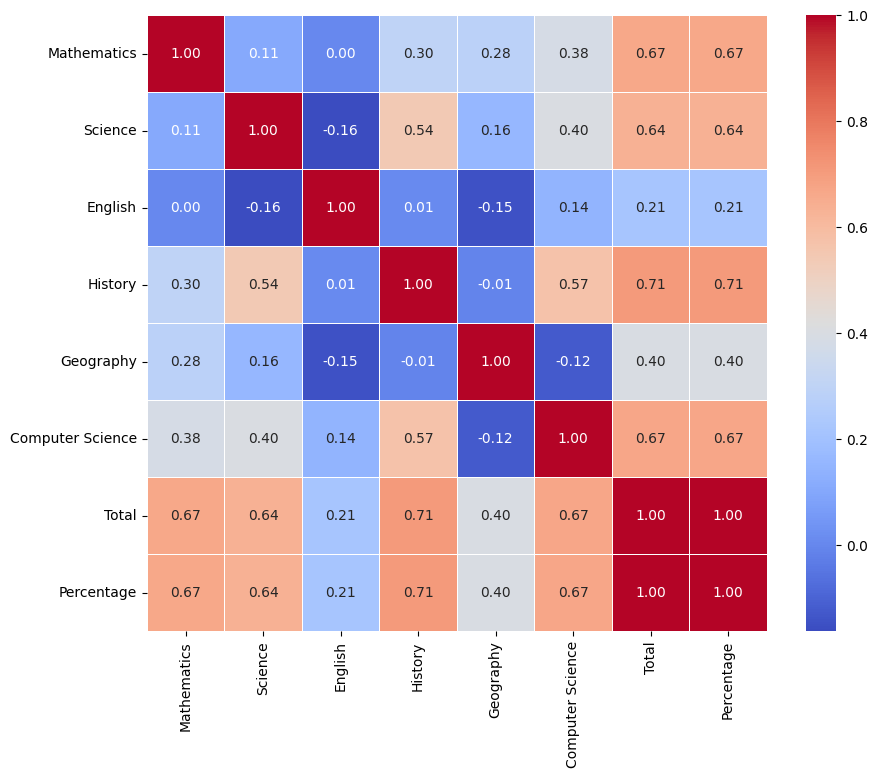

In [73]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.show()

In [74]:
from  sklearn.preprocessing import  MinMaxScaler

In [75]:
scaler=MinMaxScaler()

data=scaler.fit_transform(df)
data


array([[0.72727273, 0.28      , 0.27027027, 0.59459459, 0.77777778,
        0.48275862, 0.68639053, 0.68654597],
       [0.54545455, 1.        , 0.40540541, 0.94594595, 0.22222222,
        0.55172414, 0.81065089, 0.81079162],
       [0.76363636, 0.46      , 0.02702703, 0.27027027, 1.        ,
        0.        , 0.6035503 , 0.60347888],
       [1.        , 0.16      , 0.        , 0.43243243, 0.04444444,
        0.48275862, 0.44970414, 0.44976926],
       [0.52727273, 0.72      , 0.81081081, 0.40540541, 0.71111111,
        0.51724138, 0.81656805, 0.81647142],
       [0.65454545, 0.62      , 0.48648649, 0.81081081, 0.46666667,
        0.93103448, 0.85207101, 0.85197018],
       [0.34545455, 0.34      , 0.62162162, 0.51351351, 0.57777778,
        0.06896552, 0.5147929 , 0.51473198],
       [0.85454545, 0.86      , 0.37837838, 0.64864865, 0.75555556,
        0.62068966, 0.95266272, 0.95278665],
       [0.58181818, 0.24      , 0.94594595, 0.18918919, 0.42222222,
        0.37931034, 0.573964

In [76]:
dff=pd.DataFrame(data,columns=df.columns)
dff

,Mathematics,Science,English,History,Geography,Computer Science,Total,Percentage
0,0.727273,0.28,0.270270,0.594595,0.777778,0.482759,0.686391,0.686546
1,0.545455,1.00,0.405405,0.945946,0.222222,0.551724,0.810651,0.810792
2,0.763636,0.46,0.027027,0.270270,1.000000,0.000000,0.603550,0.603479
3,1.000000,0.16,0.000000,0.432432,0.044444,0.482759,0.449704,0.449769
4,0.527273,0.72,0.810811,0.405405,0.711111,0.517241,0.816568,0.816471
5,0.654545,0.62,0.486486,0.810811,0.466667,0.931034,0.852071,0.851970
6,0.345455,0.34,0.621622,0.513514,0.577778,0.068966,0.514793,0.514732
7,0.854545,0.86,0.378378,0.648649,0.755556,0.620690,0.952663,0.952787
8,0.581818,0.24,0.945946,0.189189,0.422222,0.379310,0.573964,0.574015
9,0.436364,0.52,0.189189,0.864865,0.622222,0.827586,0.721893,0.722045


In [77]:
from sklearn.decomposition import PCA
import numpy as np

In [78]:
pca=PCA(n_components=2)
dff=pca.fit_transform(dff)
dff

# np.sum(pca.explained_variance_ratio_)


array([[ 0.04383684, -0.22158336],
       [ 0.47879004,  0.05920807],
       [-0.29921883, -0.72117134],
       [-0.30005811, -0.03726642],
       [ 0.20647429,  0.13515058],
       [ 0.55392065,  0.16892011],
       [-0.4183321 ,  0.05933467],
       [ 0.60482179, -0.24549245],
       [-0.33989003,  0.4543849 ],
       [ 0.32024184, -0.11187628],
       [ 0.18762204,  0.14391291],
       [-0.08315524,  0.01626076],
       [-0.15798458,  0.00905809],
       [ 0.40885662, -0.26388553],
       [-0.10812656, -0.2981917 ],
       [ 0.29170062,  0.65634385],
       [ 0.05195359,  0.03415296],
       [-0.05788715, -0.25002964],
       [ 0.39219047,  0.59241372],
       [ 0.19264245, -0.60414129],
       [-1.1651948 ,  0.27610185],
       [ 0.77369313,  0.23371581],
       [-0.27700152, -0.20124103],
       [ 0.08802892,  0.03095691],
       [ 0.50786757, -0.15454577],
       [-0.37385125,  0.2792639 ],
       [ 0.15335271,  0.15607649],
       [-0.74323724,  0.13300187],
       [ 0.42457945,